In [11]:
# Sales Forecasting Pipeline with Fine-Tuning and Model Saving

# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

!pip install pmdarima
import pmdarima as pm
import warnings
warnings.filterwarnings("ignore")

In [12]:
# Step 2: Load data
df = pd.read_csv('mock_kaggle.csv', parse_dates=['data'])
df = df.rename(columns={
    'data': 'Date',
    'venda': 'Sales',
    'estoque': 'Stock',
    'preco': 'Price'
})
df.sort_values('Date', inplace=True)
df.reset_index(drop=True, inplace=True)

In [13]:
# Step 3: Data Cleaning & Feature Engineering
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)

# Create lag features on Sales column
df['Sales_Lag7'] = df['Sales'].shift(7)
df['Sales_Lag30'] = df['Sales'].shift(30)

# Create rolling average features for recent sales trends
df['Sales_7d_Mean'] = df['Sales'].rolling(window=7).mean()
df['Sales_30d_Mean'] = df['Sales'].rolling(window=30).mean()

# Drop rows with NaN values (created by lag and rolling calculations)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

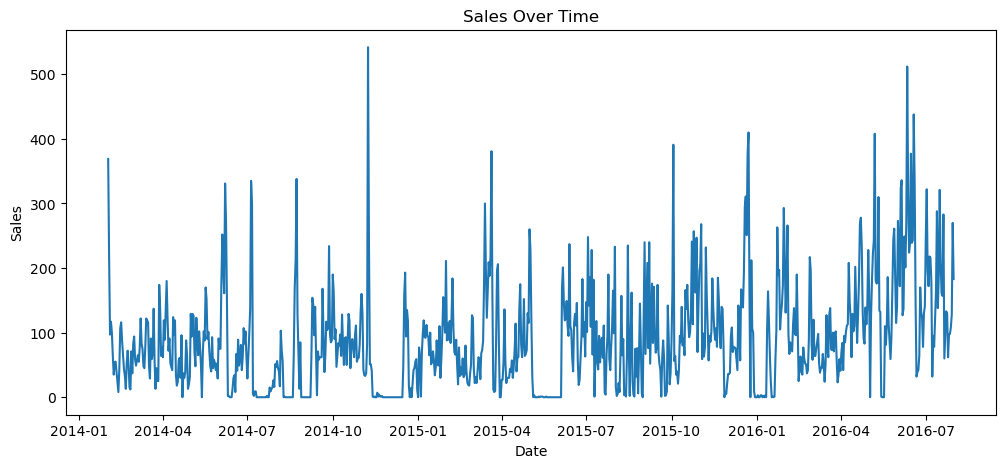

                                Date       Sales        Stock       Price  \
count                            907  907.000000   907.000000  907.000000   
mean   2015-05-04 16:24:20.639470848   89.134509  1521.721058    1.607211   
min              2014-02-01 00:00:00    0.000000     0.000000    0.000000   
25%              2014-09-20 12:00:00   31.000000   788.500000    1.290000   
50%              2015-05-05 00:00:00   73.000000  1311.000000    1.390000   
75%              2015-12-17 12:00:00  125.000000  1902.500000    1.890000   
max              2016-07-31 00:00:00  542.000000  7228.000000    2.980000   
std                              NaN   80.713455  1284.327170    0.531633   

            Month   DayOfWeek   IsWeekend  Sales_Lag7  Sales_Lag30  \
count  907.000000  907.000000  907.000000  907.000000   907.000000   
mean     6.140022    3.014333    0.287762   89.502756    88.117971   
min      1.000000    0.000000    0.000000    0.000000     0.000000   
25%      3.000000    1.000

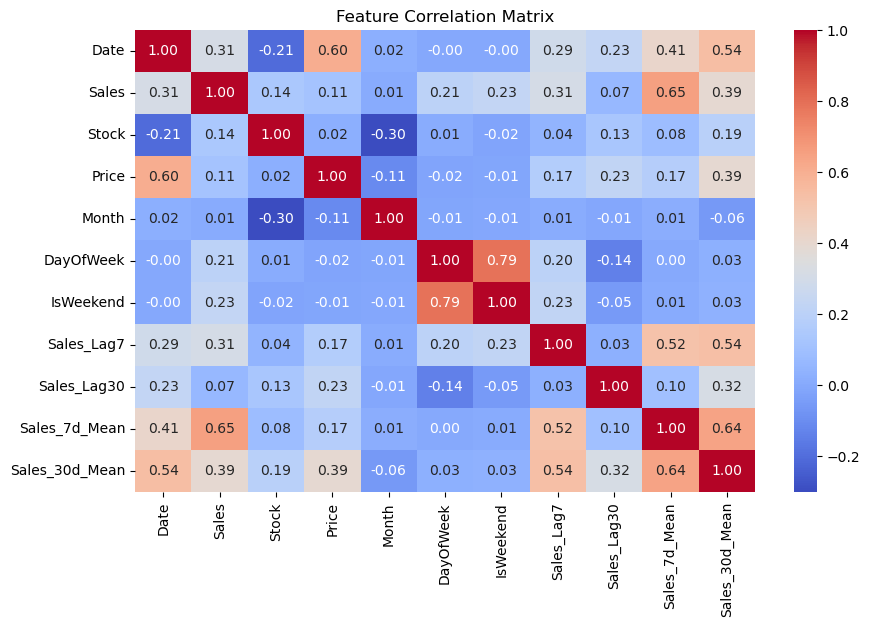

In [14]:
# Step 4: Exploratory Data Analysis (EDA)
plt.figure(figsize=(12,5))
plt.plot(df['Date'], df['Sales'])
plt.xlabel('Date')
plt.ylabel('Sales')
plt.title('Sales Over Time')
plt.show()

print(df.describe())

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Feature Correlation Matrix')
plt.show()

In [15]:
# Step 5: Model preparation and baseline training (Random Forest)
features_rf = ['Month', 'DayOfWeek', 'IsWeekend', 'Sales_Lag7', 'Sales_Lag30', 
               'Sales_7d_Mean', 'Sales_30d_Mean', 'Stock', 'Price']

X = df[features_rf]
y = df['Sales']

# Time series split: 80% train, 20% test
split_idx = int(len(df) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Train baseline Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

Baseline Random Forest Performance:
MAE: 50.788
RMSE: 69.459
R2 Score: 0.404


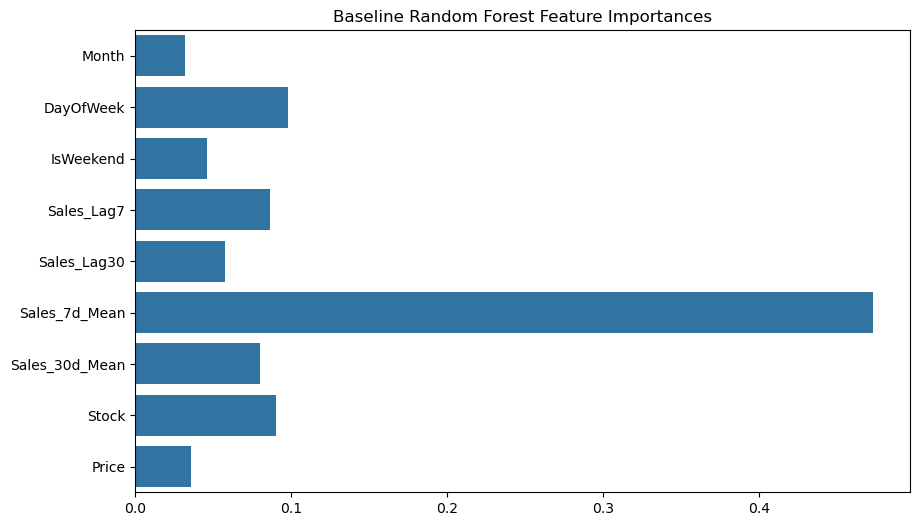

In [16]:
# Predict on test set and evaluate
y_pred_rf = rf_model.predict(X_test)

print("Baseline Random Forest Performance:")
print(f"MAE: {mean_absolute_error(y_test, y_pred_rf):.3f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred_rf, squared=False):.3f}")
print(f"R2 Score: {r2_score(y_test, y_pred_rf):.3f}")

plt.figure(figsize=(10,6))
sns.barplot(x=rf_model.feature_importances_, y=features_rf)
plt.title('Baseline Random Forest Feature Importances')
plt.show()

<Figure size 1200x500 with 0 Axes>

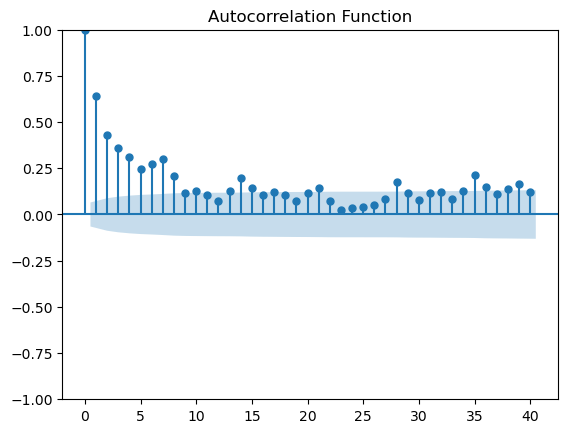

<Figure size 1200x500 with 0 Axes>

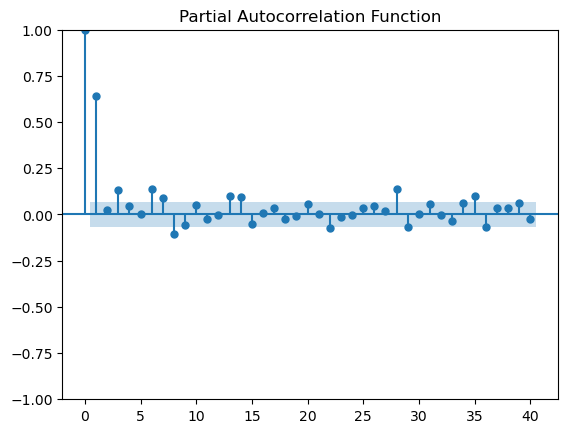

In [17]:
# Step 6: ARIMA baseline model training and evaluation
series = df.set_index('Date')['Sales']
train_arima = series[:split_idx]
test_arima = series[split_idx:]

plt.figure(figsize=(12,5))
plot_acf(series, lags=40)
plt.title('Autocorrelation Function')
plt.show()

plt.figure(figsize=(12,5))
plot_pacf(series, lags=40)
plt.title('Partial Autocorrelation Function')
plt.show()


Baseline ARIMA Performance:
MAE: 95.819
RMSE: 110.127


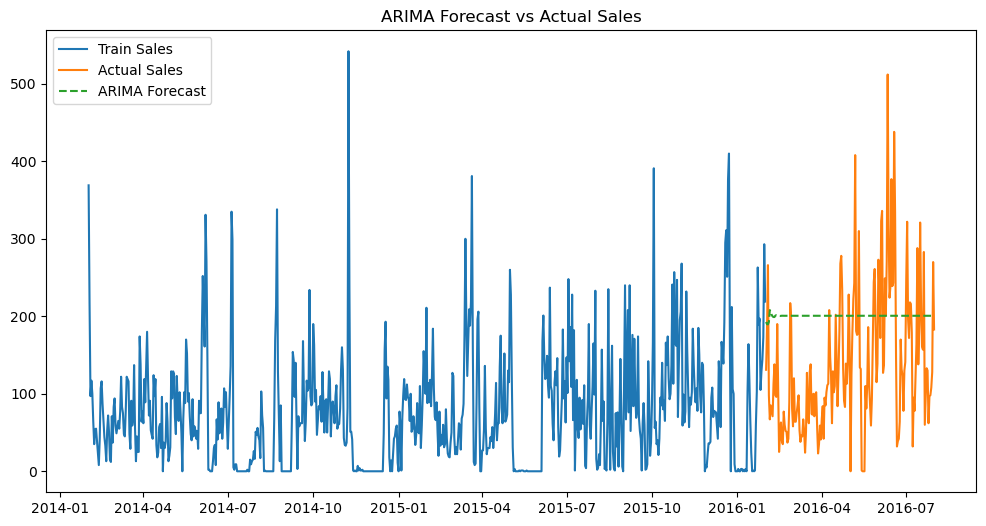

In [18]:
# Fit ARIMA with initial order (5,1,0)
arima_order = (5,1,0)
arima_model = ARIMA(train_arima, order=arima_order)
arima_model_fit = arima_model.fit()

forecast_arima = arima_model_fit.forecast(steps=len(test_arima))

print("\nBaseline ARIMA Performance:")
print(f"MAE: {mean_absolute_error(test_arima, forecast_arima):.3f}")
print(f"RMSE: {mean_squared_error(test_arima, forecast_arima, squared=False):.3f}")

plt.figure(figsize=(12,6))
plt.plot(train_arima.index, train_arima, label='Train Sales')
plt.plot(test_arima.index, test_arima, label='Actual Sales')
plt.plot(test_arima.index, forecast_arima, label='ARIMA Forecast', linestyle='--')
plt.legend()
plt.title('ARIMA Forecast vs Actual Sales')
plt.show()

Starting Random Forest hyperparameter tuning...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best Random Forest parameters found:
{'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 30}

Tuned Random Forest Performance:
MAE: 55.032
RMSE: 75.699
R2 Score: 0.292


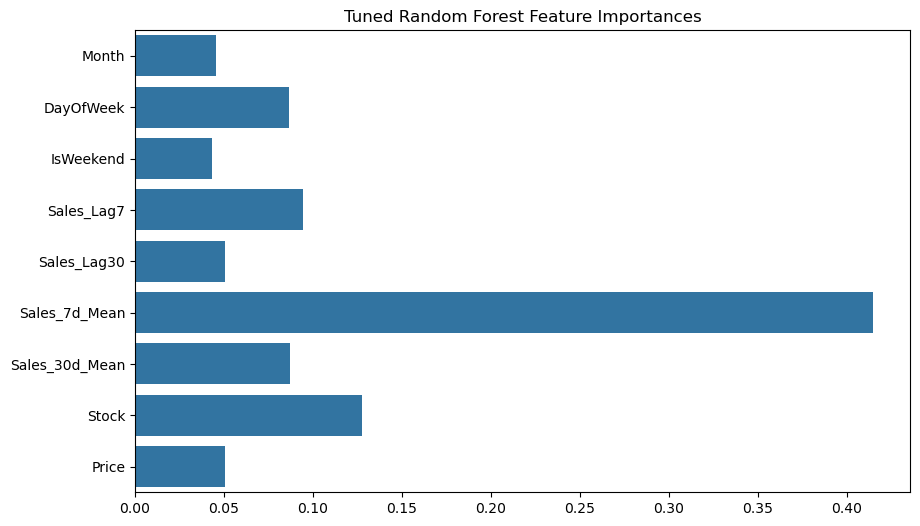

In [19]:
# Step 7: Fine-tune Random Forest hyperparameters
param_dist = {
    'n_estimators': [100, 200, 400, 800],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2']
}

print("Starting Random Forest hyperparameter tuning...")
random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("\nBest Random Forest parameters found:")
print(random_search.best_params_)

best_rf_model = random_search.best_estimator_

y_pred_tuned = best_rf_model.predict(X_test)

print("\nTuned Random Forest Performance:")
print(f"MAE: {mean_absolute_error(y_test, y_pred_tuned):.3f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred_tuned, squared=False):.3f}")
print(f"R2 Score: {r2_score(y_test, y_pred_tuned):.3f}")

plt.figure(figsize=(10,6))
sns.barplot(x=best_rf_model.feature_importances_, y=features_rf)
plt.title('Tuned Random Forest Feature Importances')
plt.show()

In [20]:
# Save tuned Random Forest model for deployment
joblib.dump(best_rf_model, 'sales_forecast_rf_model_tuned.pkl')
print("Tuned Random Forest model saved as 'sales_forecast_rf_model_tuned.pkl'")

Tuned Random Forest model saved as 'sales_forecast_rf_model_tuned.pkl'


In [ ]:
# Step 8: Auto ARIMA parameter tuning using pmdarima
print("Starting ARIMA auto-parameter tuning...")
auto_arima_model = pm.auto_arima(
    train_arima,
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    n_jobs=-1,
    trace=True
)

print(f"Best ARIMA order found: {auto_arima_model.order}")

arima_model_auto = ARIMA(train_arima, order=auto_arima_model.order).fit()

forecast_auto = arima_model_auto.forecast(steps=len(test_arima))

print("\nAuto-tuned ARIMA Performance:")
print(f"MAE: {mean_absolute_error(test_arima, forecast_auto):.3f}")
print(f"RMSE: {mean_squared_error(test_arima, forecast_auto, squared=False):.3f}")

plt.figure(figsize=(12,6))
plt.plot(train_arima.index, train_arima, label='Train Sales')
plt.plot(test_arima.index, test_arima, label='Actual Sales')
plt.plot(test_arima.index, forecast_auto, label='Auto ARIMA Forecast', linestyle='--')
plt.legend()
plt.title('Auto ARIMA Forecast vs Actual Sales')
plt.show()


Starting ARIMA auto-parameter tuning...
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.46 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8098.769, Time=0.06 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8068.202, Time=0.32 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8040.411, Time=0.38 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8096.777, Time=0.05 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.68 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=7990.118, Time=0.37 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.88 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=7982.059, Time=0.60 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.16 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=1.63 sec
